In [ ]:
%pip install pandas matplotlib seaborn scikit-learn openpyxl numpy

In [ ]:
# PARTIE 1 : PRÉTRAITEMENT DES DONNÉES
import pandas as pd
from sklearn.preprocessing import StandardScaler

# chargement des données
df = pd.read_excel('ai4i2020.xlsx' , header=1)

# encodage ordinal
mapping_type = {'L': 0, 'M': 1, 'H': 2}               # Low = 0, Medium = 1, high = 2
df['Type_code'] = df['Type'].map(mapping_type)

# Variables explicatives et variable réponse
colonnes_X = ['Type_code', 'Air temperature [K]', 
				'Process temperature [K]', 'Rotational speed [rpm]', 
					'Torque [Nm]', 'Tool wear [min]']

X = df[colonnes_X]						# variables explicatives
y = df['Machine failure']				# variable réponse

# Standardisation des données
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

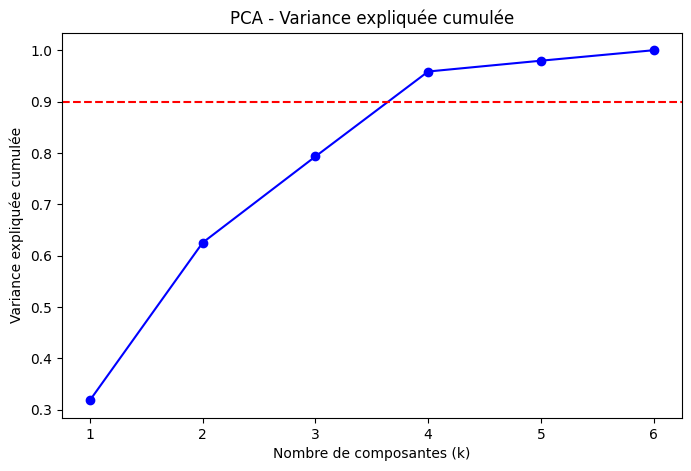

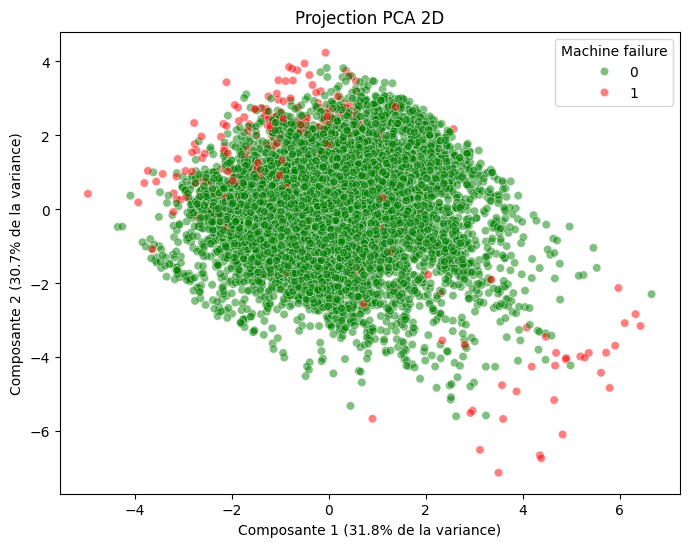

In [ ]:
# PARTIE 2 : PCA ET VISUALISATION
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.decomposition import PCA

# PCA complet
pca_complet = PCA()                                     # avec les 6 variables explicatives
pca_complet.fit(X_scaled)

variance_cumulee = np.cumsum(pca_complet.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1,7), variance_cumulee, marker='o', color='blue')
plt.axhline(y=0.90, color='red', linestyle='--')                      # seuil de 90% par convention pour choisir k
plt.xlabel('Nombre de composantes (k)')
plt.ylabel('Variance expliquée cumulée')
plt.title('PCA - Variance expliquée cumulée')
plt.show()

# PCA projection 2D (k=2)
pca = PCA(n_components=2)                # On garde seulement les 2 premières composantes pour visualiser en 2D
X_pca = pca.fit_transform(X_scaled)

# Conversion de la matrice en tableau
df_pca = pd.DataFrame(data = X_pca, columns = ['PC1', 'PC2'])
df_pca['Machine failure'] = y.values

# Graphique de projection 2D
plt.figure(figsize=(8, 6))
sns.scatterplot(data = df_pca, x = 'PC1', y = 'PC2',
                hue = 'Machine failure', palette = ['green', 'red'], alpha = 0.5)

plt.title('Projection PCA 2D')
plt.xlabel(f"Composante 1 ({pca.explained_variance_ratio_[0]*100:.1f}% de la variance)")
plt.ylabel(f"Composante 2 ({pca.explained_variance_ratio_[1]*100:.1f}% de la variance)")
plt.show()



In [ ]:

# PARTIE 3 : DIVISION DES DONNÉES (ENTRAÎNEMENT/TEST)
from sklearn.model_selection import train_test_split

# Division 80% entraînement, 20% test et maintien du ratio de défaillances
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y,
                                    test_size = 0.2, random_state = 71,
                                     stratify = y)


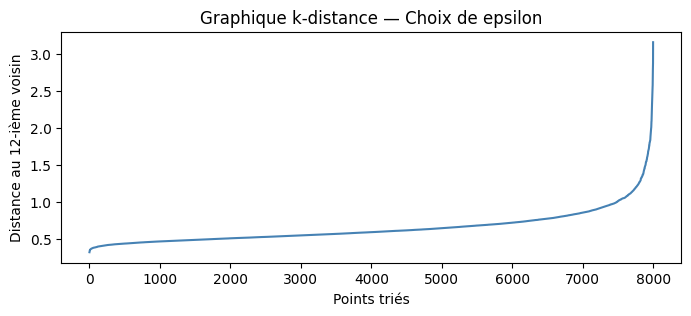

In [ ]:
# PARTIE 4 :Paramètres de DBSCAN
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
import numpy as np

min_pts = 12                                # min_pts = 2 * nombre de dimensions = 2 * 6 = 12

# Calcul des k plus proches voisins
nombres = NearestNeighbors(n_neighbors=min_pts)
nombres.fit(X_train)
distances, _ = nombres.kneighbors(X_train)

distances_k = distances[:, -1]                          # distance au k-ième plus proche voisin
distances_k_sorted = np.sort(distances_k)              # tri par odre croissant
plt.figure(figsize=(8, 3))
plt.plot(distances_k_sorted, color='steelblue')
plt.xlabel('Points triés')
plt.ylabel(f'Distance au {min_pts}-ième voisin')
plt.title('Graphique k-distance — Choix de epsilon')
plt.show()








In [ ]:
# PARTIE 5 : DBSCAN
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt

# Paramètres choisis
epsilon = 1.0
min_pts = 12

dbscan = DBSCAN(eps=epsilon, min_samples=min_pts)

# Prédiction des étiquettes
labels = dbscan.fit_predict(X_train)         # application uniquement sur les données entraînées

# Filtre pour retirer le bruit (points étiquetés -1)
filtre = labels != -1                        # retourne TRUE si le point n'est pas du bruit

# Création des données filtrées
X_train_clean = X_train[filtre]
y_train_clean = y_train[filtre]
# Résultats
total_initial = len(X_train)
total_bruit = (labels == -1).sum()
pourcentage_bruit = (total_bruit / total_initial) * 100

print(f"Total de points initiaux : {total_initial}")
print(f"Total de points considérés comme bruit : {total_bruit}")
print(f"Pourcentage de bruit retiré : {pourcentage_bruit:.2f}%")
print(f"Taille finale de X_train_clean : {len(X_train_clean)} observations")
print(f"Défaillances avant nettoyage : {y_train.sum()}")
print(f"Défaillances après nettoyage : {y_train_clean.sum()}")
print(f"Défaillances retirées : {y_train.sum() - y_train_clean.sum()}")
print(f"Pourcentage de défaillances conservées : {(y_train_clean.sum() / y_train.sum()) * 100:.2f}%")


Total de points initiaux : 8000
Total de points considérés comme bruit : 202
Pourcentage de bruit retiré : 2.53%
Taille finale de X_train_clean : 7798 observations
Défaillances avant nettoyage : 271
Défaillances après nettoyage : 230
Défaillances retirées : 41
Pourcentage de défaillances conservées : 84.87%


In [ ]:
# PARTIE 6 : OPTIMISATION DES HYPERPARAMÈTRES POUR SVM
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

#Grilles d'hyperparamètres
grille = {
    'C': [0.1, 1, 10],                       # pénalité de l'erreur
    'gamma': [0.01, 0.1, 1],                 # influence locale
    'kernel': ['rbf'],                       # noyau non linéaire. utilisation justifiée par PCA
    'class_weight': ['balanced']             # gestion du déséquilibre des classes
}

# SVM pour les deux modèles (brute et nettoyée)
svm_brute = SVC(probability=True, random_state=71)
svm_clean = SVC(probability=True, random_state=71)

# GridSearchCV pour les deux modèles
grid_search_brute = GridSearchCV(estimator=svm_brute, 
                           param_grid=grille, 
                           cv=5,                        # validation croisée à 5 plis
                           scoring='f1',                # optimisation du F1-score
                           n_jobs=-1)

grid_search_clean = GridSearchCV(estimator=svm_clean, 
                           param_grid=grille, 
                           cv=5,                        
                           scoring='f1',                
                           n_jobs=-1)

# Modèle 1 : Entraînement sur les données brutes (X_train, y_train)
grid_search_brute.fit(X_train, y_train)
meilleur_svm_brute = grid_search_brute.best_estimator_        # on garde le meilleur modèle trouvé

print(f"Meilleurs paramètres pour SVM 1 (données brutes) : {grid_search_brute.best_params_}")

# Modèle 2 : Entraînement sur les données nettoyées (X_train_clean, y_train_clean)
grid_search_clean.fit(X_train_clean, y_train_clean)
meilleur_svm_clean = grid_search_clean.best_estimator_       # on garde le meilleur modèle trouvé

print(f"Meilleurs paramètres pour SVM 2 (données nettoyées) : {grid_search_clean.best_params_}")

Meilleurs paramètres pour SVM 1 (données brutes) : {'C': 10, 'class_weight': 'balanced', 'gamma': 1, 'kernel': 'rbf'}
Meilleur score F1 en validation croisée pour SVM 1 (données brutes): 0.5119
Meilleurs paramètres pour SVM 2 (données nettoyées) : {'C': 10, 'class_weight': 'balanced', 'gamma': 1, 'kernel': 'rbf'}
Meilleur score F1 en validation croisée pour SVM 2 (données nettoyées): 0.5193


Métrique            SVM Brut   SVM Propre
---------------------------------------------
F1-score              0.5465       0.5000
AUC-ROC               0.9304       0.9298


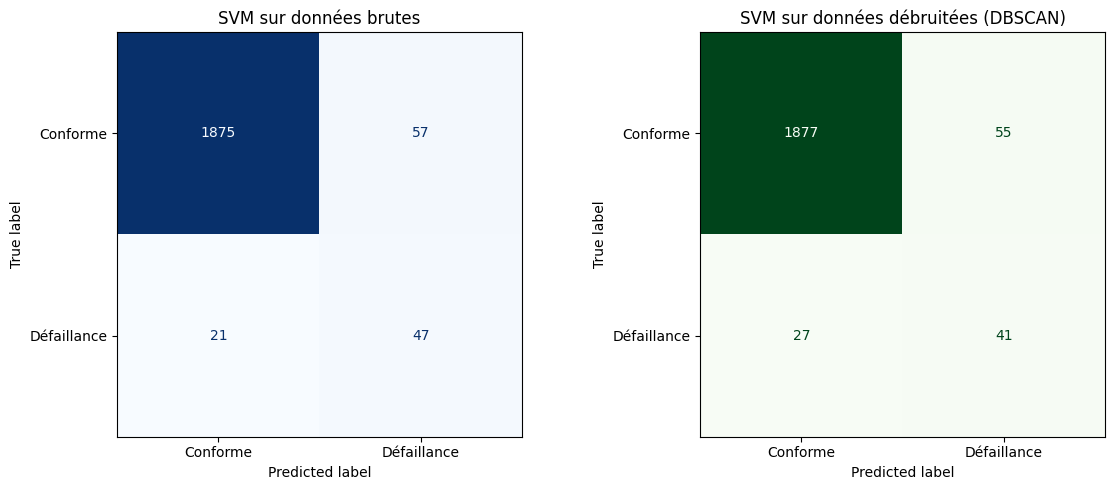

In [22]:
# PARTIE 7 : ÉVALUATION DES MODÈLES sur X_test

from sklearn.metrics import (f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

# Prédictions et probabilités
y_pred_brute = meilleur_svm_brute.predict(X_test)         # on utilise le meilleur modèle trouvé par GridSearch pour chaque SVM
y_pred_clean = meilleur_svm_clean.predict(X_test)

y_prob_brute = meilleur_svm_brute.predict_proba(X_test)[:, 1]   # probabilités pour la classe "1"
y_prob_clean = meilleur_svm_clean.predict_proba(X_test)[:, 1]


# Métriques d'évaluation

# F1-score
f1_brute = f1_score(y_test, y_pred_brute)               # calcule le F1-score pour la classe positif
f1_clean = f1_score(y_test, y_pred_clean)   

# AUC-ROC
auc_brute = roc_auc_score(y_test, y_prob_brute)        # calcule l'AUC-ROC en utilisant les probabilités prédites
auc_clean = roc_auc_score(y_test, y_prob_clean)

# Tableau comparatif entre F1-score et AUC-ROC pour les deux modèles
print(f"{'Métrique':<15} {'SVM Brut':>12} {'SVM Propre':>12}")
print("-" * 45)
print(f"{'F1-score':<15} {f1_brute:>12.4f} {f1_clean:>12.4f}")
print(f"{'AUC-ROC':<15} {auc_brute:>12.4f} {auc_clean:>12.4f}")

# Matrices de confusion
fig, axes = plt.subplots(1, 2, figsize=(12, 5))             # deux sous-graphiques côte à côte pour comparer

# Matrice pour le modèle brut
cm_brute = confusion_matrix(y_test, y_pred_brute)
disp_brute = ConfusionMatrixDisplay(confusion_matrix = cm_brute, display_labels = ['Conforme', 'Défaillance'])
disp_brute.plot(ax = axes[0], cmap = 'Blues', colorbar = False)
axes[0].set_title("SVM sur données brutes")

# Matrice pour le modèle nettoyé
cm_clean = confusion_matrix(y_test, y_pred_clean)
disp_clean = ConfusionMatrixDisplay(confusion_matrix = cm_clean, display_labels = ['Conforme', 'Défaillance'])
disp_clean.plot(ax = axes[1], cmap = 'Greens', colorbar = False)
axes[1].set_title("SVM sur données débruitées (DBSCAN)")

plt.tight_layout()
plt.show()

